In [18]:
import numpy as np
from skimage import io
import matplotlib.pyplot as plt

(2251, 2250, 2)


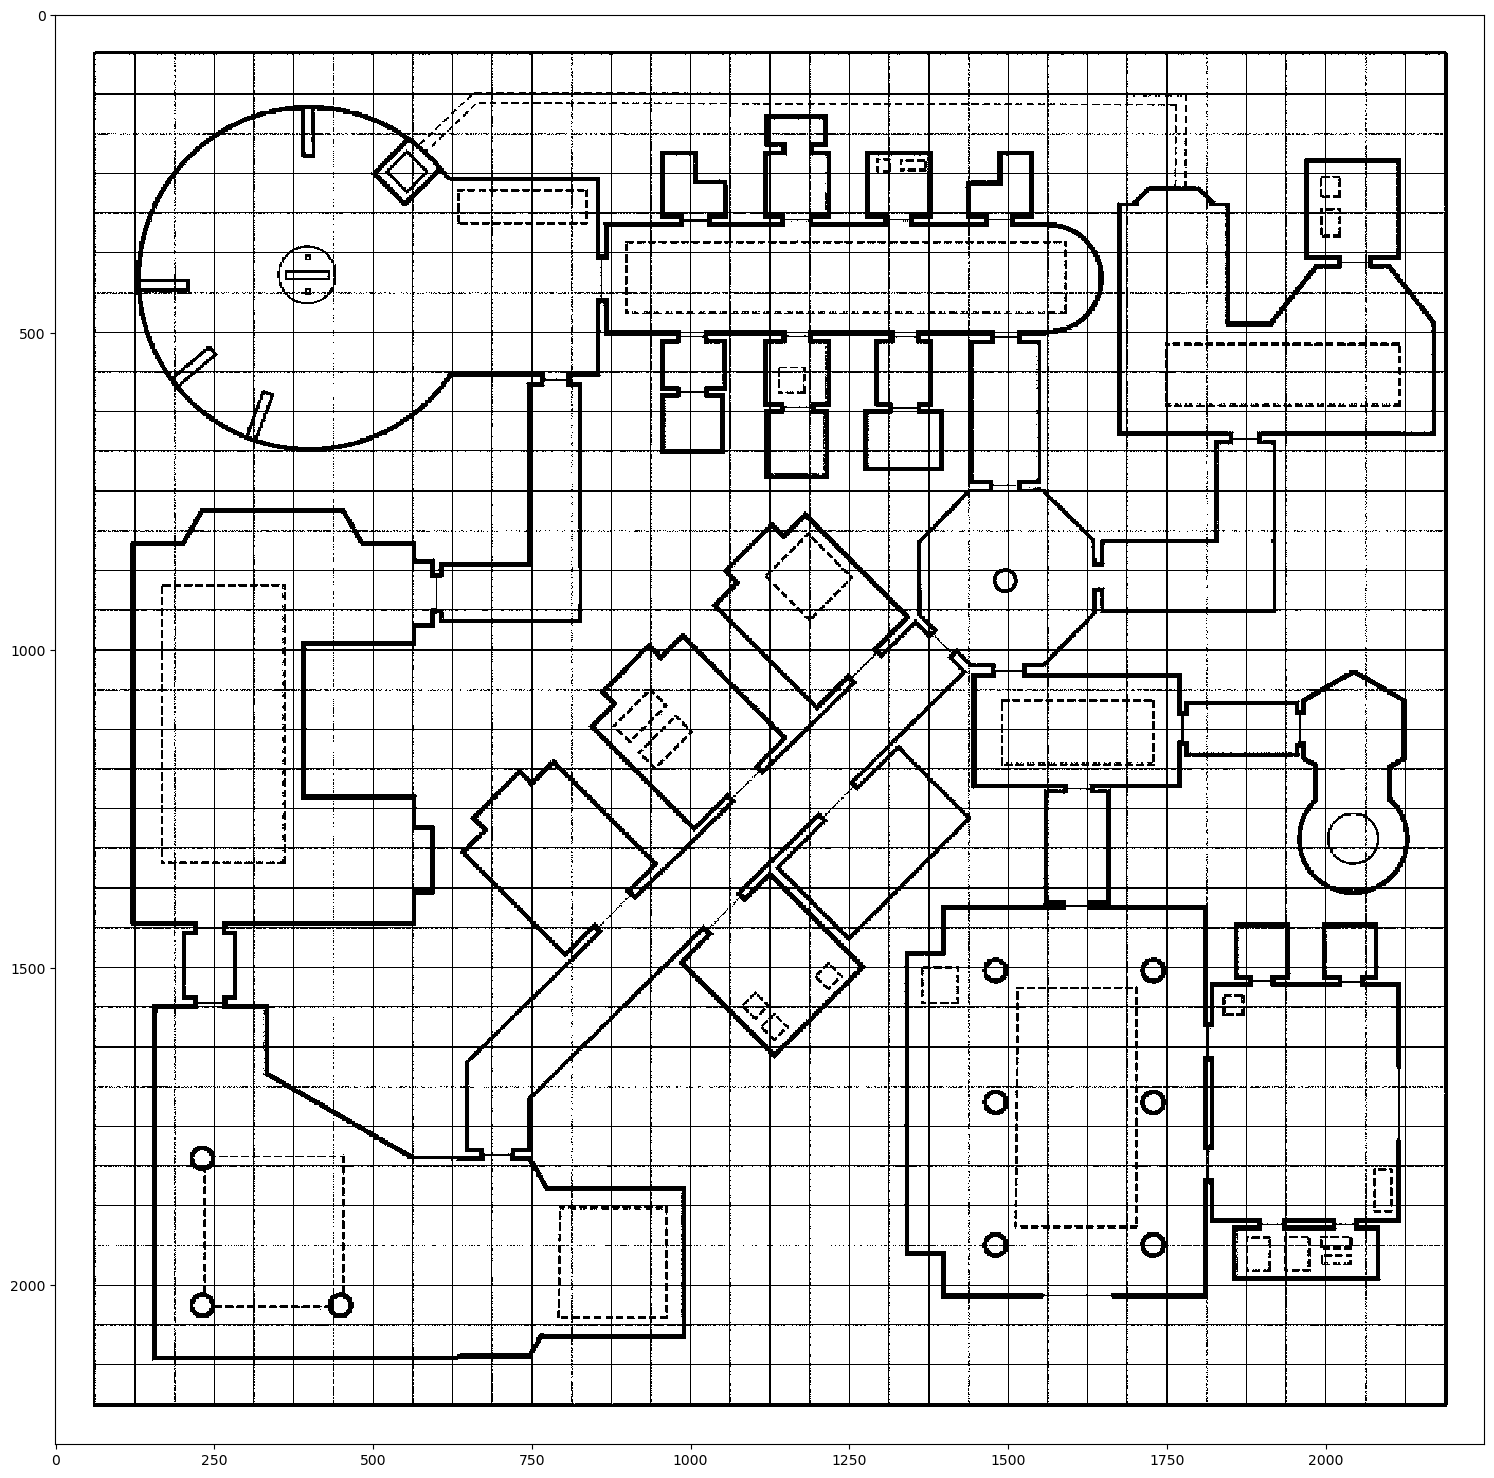

In [29]:

station = io.imread("Armaros station.png").astype(np.float32)
print(station.shape)

plt.figure(figsize=(15,15))

io.imshow(station[:,:,0].astype(np.uint8))


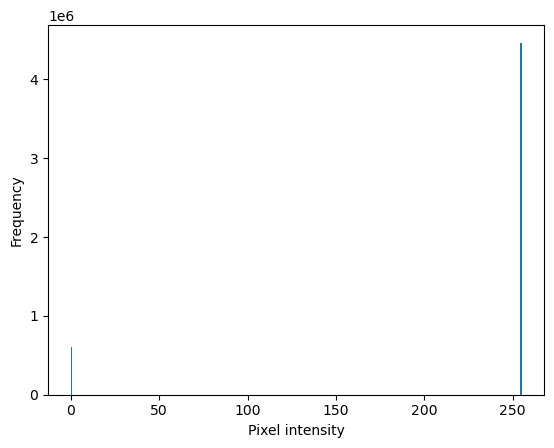

In [28]:
plt.hist(station[:,:,0].ravel(), bins=256)
plt.xlabel("Pixel intensity")
plt.ylabel("Frequency")
plt.show()

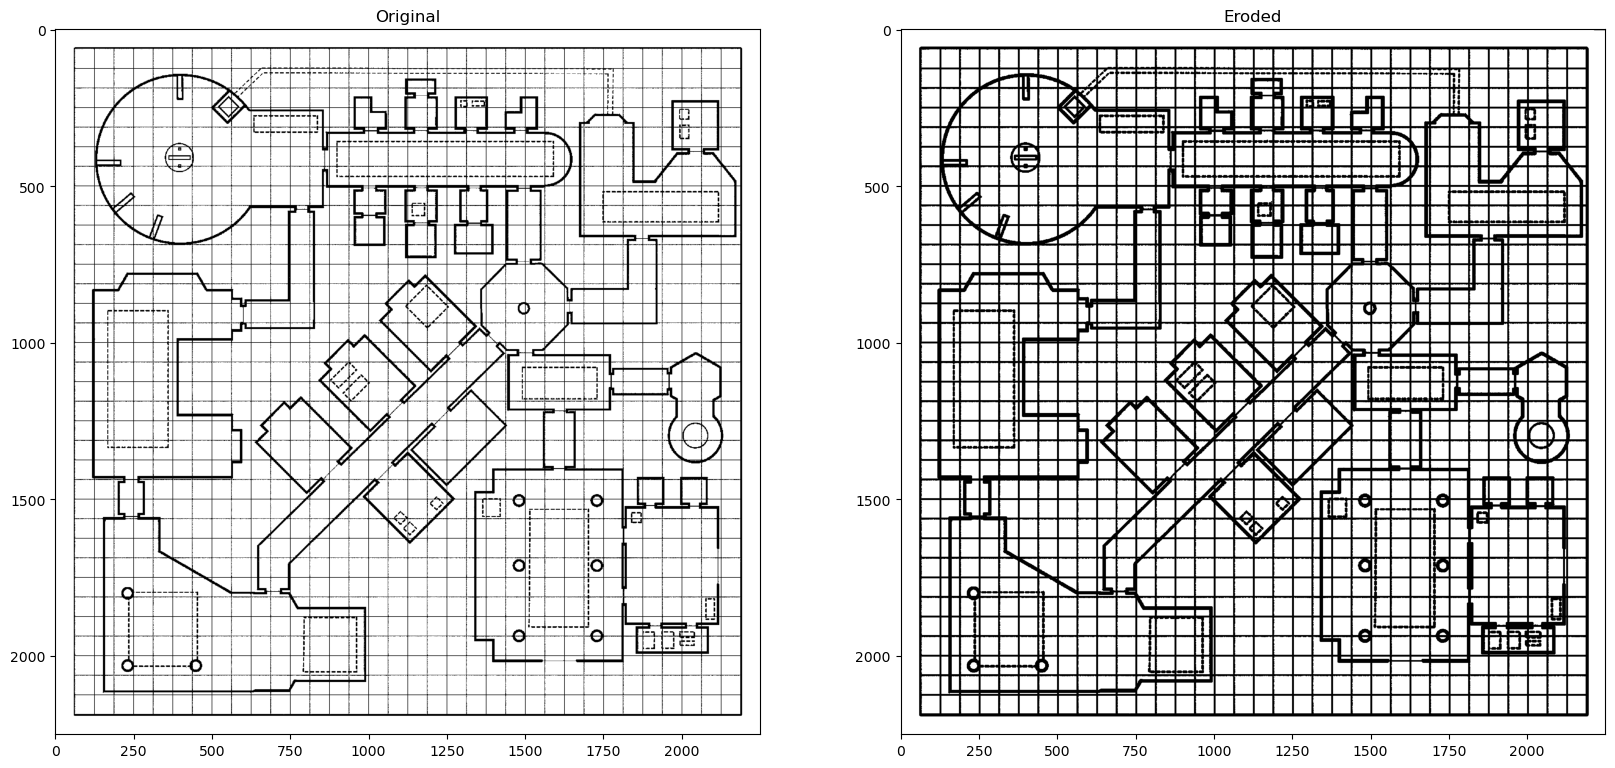

In [43]:
from skimage.morphology import dilation, disk, erosion, opening, closing
import matplotlib.pyplot as plt

dilated = erosion(station[:,:,0], footprint=disk(2))

plt.figure(figsize=(20, 20))
plt.subplot(1, 2, 1)
plt.imshow(station[:,:,0], cmap='gray')
plt.title("Original")

plt.subplot(1, 2, 2)
plt.imshow(dilated, cmap='gray')
plt.title("Eroded")
plt.savefig('map.png')
plt.show()

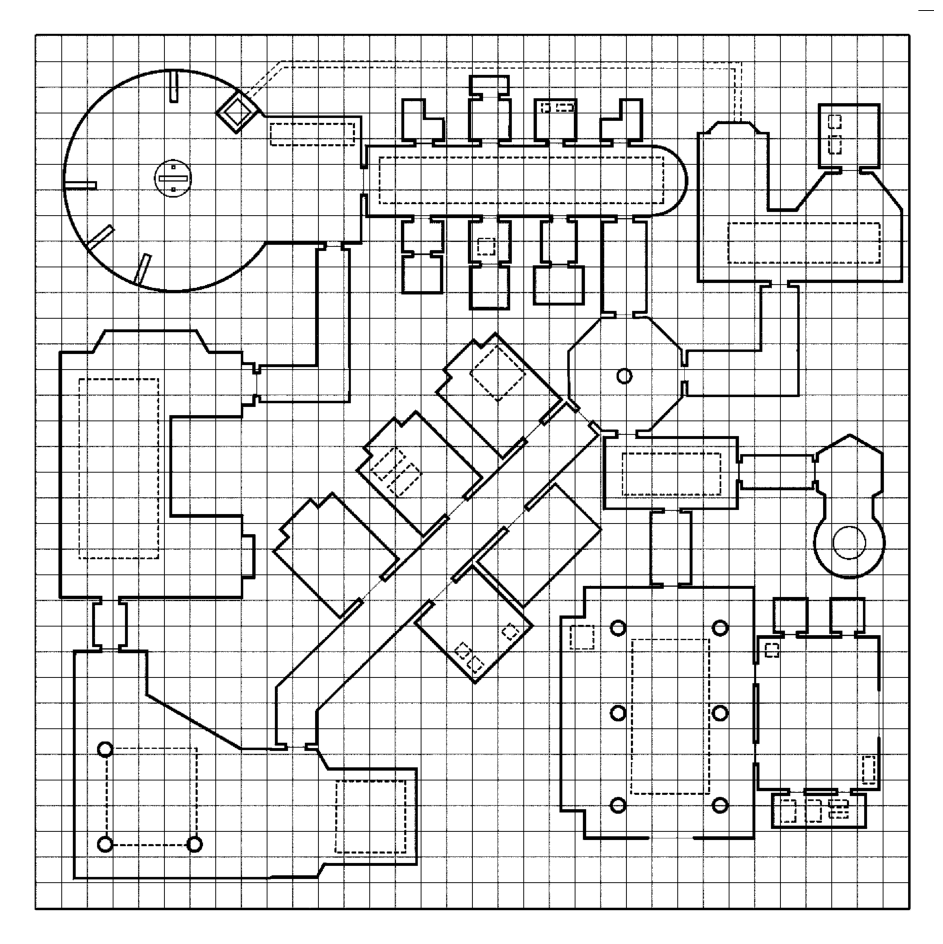

In [46]:
import cv2
import matplotlib.pyplot as plt

img = station[:, :, 0]

scale = 1

upscaled = cv2.resize(
    img,
    None,
    fx=scale,
    fy=scale,
    interpolation=cv2.INTER_LANCZOS4
)

plt.figure(figsize=(12, 12))
plt.imshow(upscaled, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.savefig('map-interp.png')
plt.show()

# TV regularised inverse problem

In [ ]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image


def superresolve_lines(
    image,
    scale=4,
    steps=1500,
    lr=0.03,
    lambda_tv=0.002,
    lambda_binary=0.005,
    device=None,
):
    """
    Optimisation-based super-resolution for binary line drawings.

    Parameters
    ----------
    image : ndarray, shape (H, W)
        Binary image, black lines on white background (0/1 or 0/255).
    scale : int
        Upscaling factor.
    steps : int
        Number of optimisation iterations.
    lr : float
        Learning rate.
    lambda_tv : float
        Total variation regularisation strength.
    lambda_binary : float
        Binary-image regularisation strength.

    Returns
    -------
    result : ndarray
        High-resolution grayscale reconstruction in [0, 1].
    losses : list
        Optimisation loss history.
    """

    if device is None:
        device = (
            "cuda" if torch.cuda.is_available()
            else "mps" if torch.backends.mps.is_available()
            else "cpu"
        )

    image = np.asarray(image, dtype=np.float32)

    if image.max() > 1:
        image /= 255.0

    y = torch.tensor(image, device=device)[None, None]
    H, W = image.shape

    # Initialise with bicubic interpolation
    # x_init = F.interpolate(
    #     y,
    #     size=(H * scale, W * scale),
    #     mode="bicubic",
    #     align_corners=False,
    # ).clamp(0.001, 0.999)
    x_init = F.interpolate(
        y.cpu(),
        size=(H * scale, W * scale),
        mode="bicubic",
        align_corners=False,
    ).clamp(0.001, 0.999).to(device)

    # Optimise logits to keep pixel values in [0, 1]
    z = torch.nn.Parameter(torch.logit(x_init))
    optimizer = torch.optim.Adam([z], lr=lr)

    losses = []

    for step in range(steps):
        optimizer.zero_grad()

        x = torch.sigmoid(z)

        # Forward model: downsample reconstructed image
        y_pred = F.interpolate(
            x,
            size=(H, W),
            mode="area",
        )

        # Data fidelity
        loss_data = F.mse_loss(y_pred, y)

        # Total variation regularisation
        tv_h = torch.abs(x[:, :, 1:, :] - x[:, :, :-1, :]).mean()
        tv_w = torch.abs(x[:, :, :, 1:] - x[:, :, :, :-1]).mean()
        loss_tv = tv_h + tv_w

        # Encourage binary pixel values
        loss_binary = (x * (1 - x)).mean()

        loss = (
            loss_data
            + lambda_tv * loss_tv
            + lambda_binary * loss_binary
        )

        loss.backward()
        optimizer.step()

        losses.append(loss.item())

        if step % 250 == 0 or step == steps - 1:
            print(
                f"Step {step:4d} | "
                f"Data: {loss_data.item():.6f} | "
                f"TV: {loss_tv.item():.6f} | "
                f"Binary: {loss_binary.item():.6f}"
            )

    result = torch.sigmoid(z).detach().cpu().numpy()[0, 0]

    return result, losses


# ============================================================
# Apply super-resolution
# ============================================================

# Input: existing image array, shape (H, W, C) or (H, W)
image = station[:, :, 0] if station.ndim == 3 else station

# Convert to binary
threshold = 0.5 if np.max(image) <= 1 else 127
binary = (image > threshold).astype(np.float32)

# Reconstruct at 4x resolution
result, losses = superresolve_lines(
    binary,
    scale=4,
    steps=1500,
    lr=0.03,
    lambda_tv=0.002,
    lambda_binary=0.005,
)

# ============================================================
# Save results
# ============================================================

# Grayscale reconstruction
result_uint8 = (np.clip(result, 0, 1) * 255).astype(np.uint8)
Image.fromarray(result_uint8).save("station_superresolved.png")

# Strictly binary reconstruction
binary_hr = (result > 0.5).astype(np.uint8) * 255
Image.fromarray(binary_hr).save("station_superresolved_binary.png")

# ============================================================
# Visualisation
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

axes[0].imshow(binary, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original")

axes[1].imshow(result, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Super-resolved (4×)")

axes[2].imshow(binary_hr, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Super-resolved (binary)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Optimisation history
plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Optimisation history")
plt.yscale("log")
plt.tight_layout()
plt.show()

Step    0 | Data: 0.002530 | TV: 0.022276 | Binary: 0.013516
Step  250 | Data: 0.001431 | TV: 0.022379 | Binary: 0.011753
